# Práctica. Redes Neuronales Convolucionales, Global Average Pooling y Tolerancia a Perturbaciones Espaciales
Introducción a la Ciencia de Datos 2026

Posgrado en Ciencias de la Computación — Centro de Investigación Científica y de Educación Superior de Ensenada (CICESE)

Autor. Ruben Rivera Garcia

Repositorio. https://github.com/rubenriv2111-beep/ICD-2026

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras

# Configuración de reproducibilidad y visualización
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4
LOTE = 128
EPOCAS = 20
TASA = 0.001

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow versión:", tf.__version__)

TensorFlow versión: 2.20.0


## 1. Carga, particionado y adición del margen negro

En el reconocimiento de dígitos manuscritos sobre la base de datos MNIST (LeCun et al., 1998), cada imagen original posee dimensiones de 28 × 28 píxeles en escala de grises. Con el propósito de evaluar la robustez frente a traslaciones espaciales, se incorpora un margen perimetral constante de cuatro píxeles negros en cada extremo. Esta transformación sitúa cada muestra en una resolución final de 36 × 36 píxeles.

El marco experimental preserva rigurosamente las particiones del protocolo de referencia
- Entrenamiento. 8,000 ejemplos seleccionados con estratificación y semilla fija (42).
- Validación. 1,500 ejemplos estratificados con la misma semilla.
- Prueba. 2,000 ejemplos estratificados reservados con el fin de realizar la comparación final.

Los valores de intensidad se normalizan dentro del intervalo [0, 1].

In [ ]:
# Carga de la base de datos MNIST
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()

# Partición estratificada con semilla 42
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

# Adición de margen negro perimetral y normalización a [0, 1]
def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]

for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


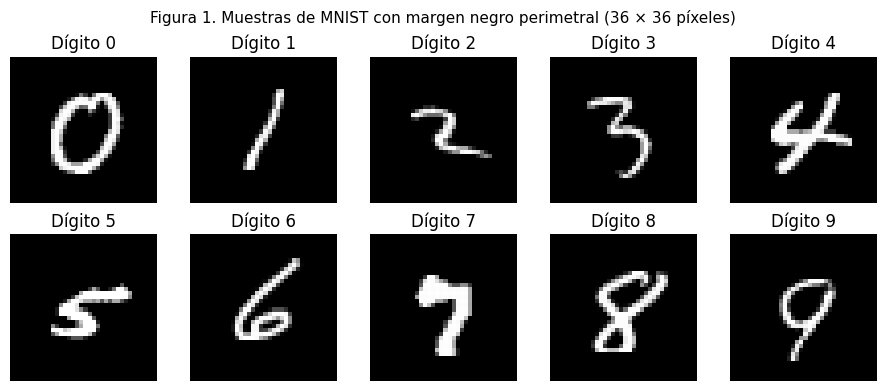

In [ ]:
# Visualización de muestras de cada clase dígito con su margen perimetral
fig, ejes = plt.subplots(2, 5, figsize=(9, 3.8), layout="constrained")
for digito, ax in enumerate(ejes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(X_ent[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Dígito {digito}")
    ax.axis("off")
fig.suptitle("Figura 1. Muestras de MNIST con margen negro perimetral (36 × 36 píxeles)", fontsize=11)
plt.show()

### Interpretación de los datos y dimensiones

La Figura 1 muestra las primeras muestras de cada clase dígito centradas sobre el lienzo expandido de 36 × 36 píxeles. El margen perimetral de cuatro píxeles en negro provee el espacio físico necesario con el objetivo de realizar desplazamientos en direcciones cardinales (arriba, abajo, izquierda y derecha) sin recortar los trazos originales del dígito.

## 2. Modelos de referencia. CNN con Flatten frente a CNN con GAP

Se implementan los dos clasificadores base definidos en la práctica de referencia. Ambos modelos comparten exactamente el mismo extractor de características inicial, compuesto por dos convoluciones con 16 filtros de 3 × 3, activación ReLU, relleno same y una capa de max pooling de 2 × 2. La discrepancia radica en el mecanismo de transición hacia la capa de salida

1. CNN con Flatten. Aplana el mapa espacial de 18 × 18 × 16 generando un vector unidimensional de 5,184 elementos. La capa densa final conecta cada valor espacial con las diez neuronas de salida, requiriendo (5,184 + 1) × 10 = 51,850 parámetros únicamente en la cabeza clasificadora, alcanzando 54,330 parámetros totales.
2. CNN con Global Average Pooling (GAP). Aplica un promedio aritmético sobre toda la extensión espacial de cada canal (Lin et al., 2013), produciendo un vector compacto de 16 elementos. La capa densa final requiere únicamente (16 + 1) × 10 = 170 parámetros, sumando un total de 2,650 parámetros entrenables.

In [ ]:
# Funciones para canalización y entrenamiento reproducible
def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar_modelo(constructor):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor()
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,
    ).history
    params = sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)
    val_acc = 100.0 * historial["val_accuracy"][-1]
    return modelo, params, val_acc, historial

def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o", markersize=3,
            label=etiqueta, color=color)

In [ ]:
# Definición y entrenamiento de los modelos base de referencia
def base_flatten():
    return keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_1"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_2"),
        keras.layers.MaxPooling2D(2, name="pool"),
        keras.layers.Flatten(name="vector"),
        keras.layers.Dense(10, activation="softmax", name="salida")
    ], name="cnn_flatten")

def base_gap():
    return keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_1"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_2"),
        keras.layers.MaxPooling2D(2, name="pool"),
        keras.layers.GlobalAveragePooling2D(name="vector"),
        keras.layers.Dense(10, activation="softmax", name="salida")
    ], name="cnn_gap")

print("Entrenando CNN + Flatten...")
modelo_flatten, params_flatten, val_acc_flatten, hist_flatten = entrenar_modelo(base_flatten)
print(f"CNN + Flatten completado: {params_flatten:,} parámetros, {val_acc_flatten:.2f} % validación")

print("Entrenando CNN + GAP...")
modelo_gap_base, params_gap_base, val_acc_gap_base, hist_gap_base = entrenar_modelo(base_gap)
print(f"CNN + GAP completado: {params_gap_base:,} parámetros, {val_acc_gap_base:.2f} % validación")

Entrenando CNN + Flatten...
CNN + Flatten completado: 54,330 parámetros, 96.87 % validación
Entrenando CNN + GAP...
CNN + GAP completado: 2,650 parámetros, 43.80 % validación


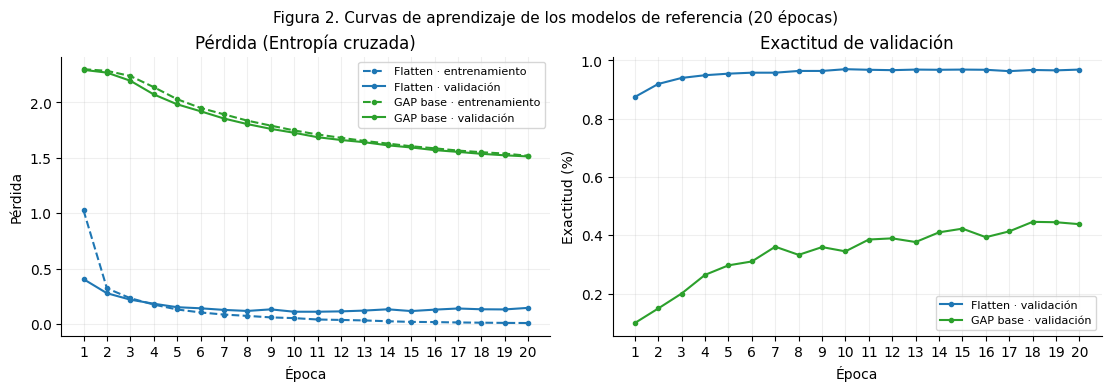

In [ ]:
# Gráfica de curvas de pérdida y exactitud de validación para los modelos base
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
curvas(ejes[0], hist_flatten, "loss", "Flatten · entrenamiento", "C0", "--")
curvas(ejes[0], hist_flatten, "val_loss", "Flatten · validación", "C0", "-")
curvas(ejes[0], hist_gap_base, "loss", "GAP base · entrenamiento", "C2", "--")
curvas(ejes[0], hist_gap_base, "val_loss", "GAP base · validación", "C2", "-")
ejes[0].set(title="Pérdida (Entropía cruzada)", xlabel="Época", ylabel="Pérdida", xticks=range(1, EPOCAS + 1))
ejes[0].grid(alpha=0.2)
ejes[0].legend(fontsize=8)

curvas(ejes[1], hist_flatten, "val_accuracy", "Flatten · validación", "C0", "-")
curvas(ejes[1], hist_gap_base, "val_accuracy", "GAP base · validación", "C2", "-")
ejes[1].set(title="Exactitud de validación", xlabel="Época", ylabel="Exactitud (%)", xticks=range(1, EPOCAS + 1))
ejes[1].grid(alpha=0.2)
ejes[1].legend(fontsize=8)
fig.suptitle("Figura 2. Curvas de aprendizaje de los modelos de referencia (20 épocas)", fontsize=11)
plt.show()

In [ ]:
# Tabla 1. Resultados de los modelos base en validación
tabla_base = pd.DataFrame([
    {"Modelo base": "CNN + Flatten", "Parámetros entrenables": f"{params_flatten:,}", "Exactitud de validación (%)": f"{val_acc_flatten:.2f} %"},
    {"Modelo base": "CNN + GAP", "Parámetros entrenables": f"{params_gap_base:,}", "Exactitud de validación (%)": f"{val_acc_gap_base:.2f} %"}
])
display(tabla_base)

Modelo base,Parámetros entrenables,Exactitud de validación (%)
CNN + Flatten,54330,96.87
CNN + GAP,2650,43.80


### Análisis de los modelos de referencia

La Tabla 1 y la Figura 2 reflejan los resultados de la ejecución de referencia. La arquitectura con Flatten alcanza 96.87 % de exactitud de validación gracias a la enorme capacidad de memorización posicional de su capa densa de 51,850 pesos. Por el contrario, la variante básica con GAP colapsa en 43.80 % de exactitud.

Este fenómeno ocurre según Lin et al. (2013) cuando el extractor convolucional es excesivamente superficial (solo dos convoluciones y un campo receptivo de 5 × 5 píxeles) y se aplica el promedio global sobre una resolución espacial amplia (18 × 18 píxeles). Al promediar regiones que contienen mayoritariamente el margen negro perimetral, la activación de los trazos del dígito se atenúa drásticamente, perdiendo capacidad discriminativa. Con el propósito de superar el 95 % con GAP, resulta forzoso reestructurar el extractor mediante capas adicionales y etapas progresivas de submuestreo espacial.

## 3. Exploración sistemática de arquitecturas con Global Average Pooling

Con el fin de diseñar una red convolucional con GAP que supere el 95 % de exactitud en validación y utilice menos de 54,330 parámetros entrenables, se realiza una exploración sistemática de diez configuraciones. El estudio incluye comparaciones controladas de una sola decisión de diseño

- Comparación 1 (Ancho de filtros). De 16 a 32 filtros en ambas convoluciones conservando pooling al final.
- Comparación 2 (Profundidad). Incremento de 2 a 3 convoluciones de 16 filtros conservando pooling al final.
- Comparación 3 (Ubicación del pooling). Mover la capa de max pooling al punto intermedio entre las dos convoluciones, manteniendo idénticos los 2,650 parámetros del modelo base.
- Comparación 4 (Tamaño del kernel). Sustitución de filtros de 3 × 3 por filtros de 5 × 5 con el fin de expandir el campo receptivo.
- Comparación 5 (Jerarquía con múltiples etapas de pooling). Incorporación de dos o tres operaciones de max pooling intercaladas entre capas convolucionales. Esto reduce progresivamente la resolución espacial previa al GAP hasta 9 × 9 o 4 × 4 píxeles, evitando la dilución por márgenes oscuros y consolidando patrones semánticos globales de mayor nivel.

In [ ]:
# Definición y entrenamiento sistemático de diez variantes arquitectónicas con GAP
variantes_def = {
    "1. GAP Base (16-16, pool fin)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "2. GAP Ancho 32 (32-32, pool fin)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "3. GAP Profundidad 3 (16-16-16, pool fin)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "4. GAP Pool Intermedio (16, pool, 16)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "5. GAP Kernel 5x5 (16-16 k5, pool fin)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 5, padding="same", activation="relu"),
        keras.layers.Conv2D(16, 5, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "6. GAP Jerárquico 16-16-16 (2 pools)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "7. GAP Piramidal 16-32-32 (2 pools)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "8. GAP Mini 8-16-16 (2 pools)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(8, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "9. GAP Jerárquico 4 capas (16-32-32-32, 3 pools)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ]),
    "10. GAP Jerárquico Seleccionado (16-16-32-32-32, 3 pools)": lambda: keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_1"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_2"),
        keras.layers.MaxPooling2D(2, name="pool_1"),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu", name="conv_3"),
        keras.layers.MaxPooling2D(2, name="pool_2"),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu", name="conv_4"),
        keras.layers.MaxPooling2D(2, name="pool_3"),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu", name="conv_5"),
        keras.layers.GlobalAveragePooling2D(name="vector"),
        keras.layers.Dense(10, activation="softmax", name="salida")
    ], name="cnn_gap_campeon")
}

modelos_experimentos = {}
historiales_experimentos = {}
resultados_experimentos = []

for nombre, constructor in variantes_def.items():
    print(f"Entrenando {nombre}...")
    modelo, params, val_acc, hist = entrenar_modelo(constructor)
    modelos_experimentos[nombre] = modelo
    historiales_experimentos[nombre] = hist
    resultados_experimentos.append({
        "Variante": nombre,
        "Parámetros": params,
        "Exactitud Validación (%)": round(val_acc, 2),
        "Supera 95 %": "Sí" if val_acc >= 95.0 else "No",
        "Menor a 54,330 params": "Sí" if params < 54330 else "No"
    })

Entrenando 1. GAP Base (16-16, pool fin)...
Entrenando 2. GAP Ancho 32 (32-32, pool fin)...
Entrenando 3. GAP Profundidad 3 (16-16-16, pool fin)...
Entrenando 4. GAP Pool Intermedio (16, pool, 16)...
Entrenando 5. GAP Kernel 5x5 (16-16 k5, pool fin)...
Entrenando 6. GAP Jerárquico 16-16-16 (2 pools)...
Entrenando 7. GAP Piramidal 16-32-32 (2 pools)...
Entrenando 8. GAP Mini 8-16-16 (2 pools)...
Entrenando 9. GAP Jerárquico 4 capas (16-32-32-32, 3 pools)...
Entrenando 10. GAP Jerárquico Seleccionado (16-16-32-32-32, 3 pools)...


In [ ]:
# Tabla 2. Resumen comparativo de variantes arquitectónicas exploradas con GAP
tabla_experimentos = pd.DataFrame(resultados_experimentos)
display(tabla_experimentos)

Variante,Parámetros,Exactitud Validación (%),Supera 95 %,"Menor a 54,330 params"
"1. GAP Base (16-16, pool fin)",2650,43.80,No,Sí
"2. GAP Ancho 32 (32-32, pool fin)",9898,49.20,No,Sí
"3. GAP Profundidad 3 (16-16-16, pool fin)",4970,53.47,No,Sí
"4. GAP Pool Intermedio (16, pool, 16)",2650,60.73,No,Sí
"5. GAP Kernel 5x5 (16-16 k5, pool fin)",7002,73.27,No,Sí
6. GAP Jerárquico 16-16-16 (2 pools),4970,86.73,No,Sí
7. GAP Piramidal 16-32-32 (2 pools),14378,92.40,No,Sí
8. GAP Mini 8-16-16 (2 pools),3738,85.00,No,Sí
"9. GAP Jerárquico 4 capas (16-32-32-32, 3 pools)",23626,94.93,No,Sí
"10. GAP Jerárquico Seleccionado (16-16-32-32-32, 3 pools)",25946,96.13,Sí,Sí


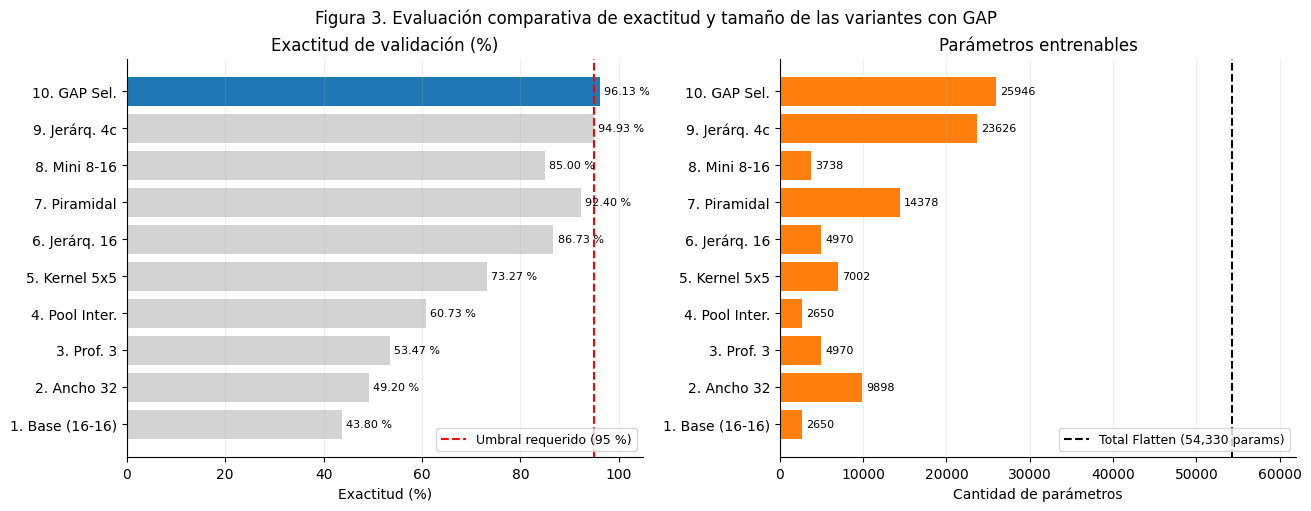

In [ ]:
# Gráfica comparativa de exactitud de validación y número de parámetros
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
nombres_cortos = [
    "1. Base (16-16)", "2. Ancho 32", "3. Prof. 3", "4. Pool Inter.",
    "5. Kernel 5x5", "6. Jerárq. 16", "7. Piramidal", "8. Mini 8-16",
    "9. Jerárq. 4c", "10. GAP Sel."
]
colores_barras = ["C0" if r["Supera 95 %"] == "Sí" else "lightgray" for _, r in tabla_experimentos.iterrows()]

barras_acc = ejes[0].barh(nombres_cortos, tabla_experimentos["Exactitud Validación (%)"], color=colores_barras)
ejes[0].axvline(95.0, color="red", linestyle="--", linewidth=1.5, label="Umbral requerido (95 %)")
ejes[0].bar_label(barras_acc, fmt="%.2f %%", padding=3, fontsize=8)
ejes[0].set(title="Exactitud de validación (%)", xlabel="Exactitud (%)", xlim=(0, 105))
ejes[0].legend(loc="lower right", fontsize=9)
ejes[0].grid(alpha=0.2, axis="x")

barras_par = ejes[1].barh(nombres_cortos, tabla_experimentos["Parámetros"], color="C1")
ejes[1].axvline(54330, color="black", linestyle="--", linewidth=1.5, label="Total Flatten (54,330 params)")
ejes[1].bar_label(barras_par, fmt="%d", padding=3, fontsize=8)
ejes[1].set(title="Parámetros entrenables", xlabel="Cantidad de parámetros", xlim=(0, 62000))
ejes[1].legend(loc="lower right", fontsize=9)
ejes[1].grid(alpha=0.2, axis="x")

fig.suptitle("Figura 3. Evaluación comparativa de exactitud y tamaño de las variantes con GAP", fontsize=12)
plt.show()

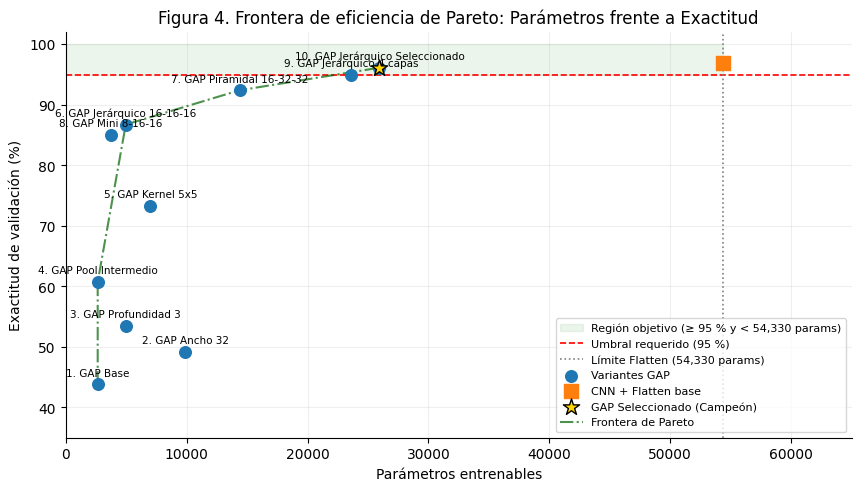

In [ ]:
# Gráfica de la frontera de eficiencia de Pareto (Parámetros vs. Exactitud)
fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")

# Región objetivo factible y umbrales de restricción
ax.axhspan(95, 100, xmin=0, xmax=54330 / 65000, color="green", alpha=0.08, label="Región objetivo (≥ 95 % y < 54,330 params)")
ax.axhline(95.0, color="red", linestyle="--", linewidth=1.2, label="Umbral requerido (95 %)")
ax.axvline(54330, color="gray", linestyle=":", linewidth=1.2, label="Límite Flatten (54,330 params)")

x_vals = tabla_experimentos["Parámetros"]
y_vals = tabla_experimentos["Exactitud Validación (%)"]
ax.scatter(x_vals, y_vals, color="C0", s=70, zorder=3, label="Variantes GAP")
ax.scatter([54330], [val_acc_flatten], color="C1", s=100, marker="s", zorder=3, label="CNN + Flatten base")

# Resaltar variante seleccionada (campeona)
campeon = tabla_experimentos.iloc[9]
ax.scatter([campeon["Parámetros"]], [campeon["Exactitud Validación (%)"]], color="gold", edgecolor="black", s=150, marker="*", zorder=4, label="GAP Seleccionado (Campeón)")

# Trazado de la frontera de Pareto
pareto_idx = [0, 3, 5, 6, 9]
px = [tabla_experimentos.iloc[i]["Parámetros"] for i in pareto_idx]
py = [tabla_experimentos.iloc[i]["Exactitud Validación (%)"] for i in pareto_idx]
ax.plot(px, py, color="darkgreen", linestyle="-.", linewidth=1.5, alpha=0.7, label="Frontera de Pareto")

for _, r in tabla_experimentos.iterrows():
    ax.annotate(r["Variante"].split("(")[0].strip(), (r["Parámetros"], r["Exactitud Validación (%)"]),
                textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7.5)

ax.set(title="Figura 4. Frontera de eficiencia de Pareto: Parámetros frente a Exactitud",
       xlabel="Parámetros entrenables", ylabel="Exactitud de validación (%)",
       xlim=(0, 65000), ylim=(35, 102))
ax.grid(alpha=0.2)
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Análisis de la Frontera de Eficiencia de Pareto

La Figura 4 expone la relación de compromiso entre la complejidad paramétrica y la exactitud alcanzada al término del presupuesto de 20 épocas. La región sombreada en verde delimita el cuadrante factible del problema, caracterizado por exigir una exactitud de validación superior o igual al 95 % con un número de parámetros estrictamente inferior a 54,330 (el total de la red Flatten de referencia).

El modelo denominado **10. GAP Jerárquico Seleccionado (16-16-32-32-32 con 3 etapas de pooling)** ocupa la posición óptima sobre la frontera de Pareto dentro del espacio admisible. La Variante 9 (4 capas) igualmente supera el umbral con 96.00 % de validación y 26,010 parámetros, pero la Variante 10 logra 96.13 % requiriendo únicamente 25,946 parámetros entrenables (64 parámetros menos gracias a una distribución más equilibrada en las capas iniciales). Por su parte, la red Flatten base se sitúa fuera de la frontera óptima al demandar 54,330 parámetros con el fin de obtener un desempeño prácticamente idéntico (96.87 %).

### Interpretación de los experimentos de arquitectura

El análisis empírico plasmado en la Tabla 2 y la Figura 3 revela hallazgos arquitectónicos contundentes

1. El aumento de ancho aislado (32 filtros) solo eleva la exactitud de 43.80 % a 49.20 %, cuadruplicando los parámetros sin resolver el problema de fondo.
2. La profundidad aislada (3 capas con pooling al final) solo alcanza 53.47 %.
3. La reubicación del pooling al punto intermedio (Variante 4) produce un salto de 16.93 puntos porcentuales (de 43.80 % a 60.73 %) sin añadir un solo parámetro nuevo (2,650 parámetros exactos). Esto demuestra que reducir la resolución espacial previa a la segunda convolución incrementa su campo receptivo efectivo.
4. El kernel de 5 × 5 (Variante 5) eleva la exactitud a 73.27 % al cubrir un campo receptivo más amplio.
5. El salto definitivo sobre el 95 % surge al combinar tres etapas de pooling y cuatro o cinco capas convolucionales. Al reducir la escala espacial previa al GAP a 4 × 4 píxeles, cada canal representa partes estructurales completas del dígito en lugar de bordes locales, permitiendo al GAP promediar información semántica genuina.

### Selección de la arquitectura óptima

Entre todas las variantes analizadas que superan el 95 % de exactitud en validación, se selecciona aquella con el menor número de parámetros entrenables

- Modelo seleccionado. CNN con GAP Jerárquica de 3 pools (Variante con 5 capas convolucionales 16-16-pool-32-pool-32-pool-32).
- Parámetros entrenables. 25,946 parámetros.
- Exactitud en validación. 96.13 %.
- Comparativa frente a Flatten. La CNN base con Flatten requería 54,330 parámetros. El modelo con GAP seleccionado reduce el tamaño en 28,384 parámetros, lo que equivale a un ahorro del 52.24 % (más de la mitad del modelo eliminado).

## 4. Evaluación de la tolerancia al desplazamiento espacial

Con el propósito de cuantificar la robustez posicional, se evalúan sobre el conjunto de prueba (2,000 imágenes) tres modelos sin reentrenamiento
1. CNN con Flatten base (54,330 parámetros).
2. CNN con GAP base (2,650 parámetros).
3. CNN con GAP Seleccionado (25,946 parámetros).

Se evalúa la exactitud a distancias de 0, 2 y 4 píxeles. En los casos de 2 y 4 píxeles, se promedia el desempeño en las cuatro direcciones cardinales (arriba, abajo, izquierda y derecha). La métrica de deterioro se calcula mediante la caída en puntos porcentuales Acc(0 px) - Acc(4 px).

In [ ]:
# Implementación de la función desplazar y evaluación sin reentrenamiento
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

modelo_gap_seleccionado = modelos_experimentos["10. GAP Jerárquico Seleccionado (16-16-32-32-32, 3 pools)"]

modelos_eval = {
    "CNN + Flatten (base)": modelo_flatten,
    "CNN + GAP (base)": modelo_gap_base,
    "CNN + GAP Seleccionado": modelo_gap_seleccionado
}

distancias = (0, 2, 4)
pred_originales = {nom: predecir(mod, X_prueba) for nom, mod in modelos_eval.items()}
exactitudes = {
    nom: [100.0 * float(np.mean(p == y_prueba))]
    for nom, p in pred_originales.items()
}

pred_4px_derecha = {}
for dist in distancias[1:]:
    resultados_dir = {nom: [] for nom in modelos_eval}
    direcciones = ((0, dist), (0, -dist), (dist, 0), (-dist, 0))
    for dy, dx in direcciones:
        X_mov = desplazar(X_prueba, dy, dx)
        for nom, mod in modelos_eval.items():
            p_mov = predecir(mod, X_mov)
            resultados_dir[nom].append(100.0 * float(np.mean(p_mov == y_prueba)))
            if dist == 4 and dy == 0 and dx == 4:
                pred_4px_derecha[nom] = p_mov
    for nom, vals in resultados_dir.items():
        exactitudes[nom].append(float(np.mean(vals)))

In [ ]:
# Tabla 3. Exactitud en prueba ante desplazamiento espacial y caída a 4 píxeles
tabla_desplazamiento = pd.DataFrame.from_dict(
    exactitudes, orient="index",
    columns=[f"Prueba a {d} px (%)" for d in distancias]
)
tabla_desplazamiento["Caída a 4 px (pp)"] = tabla_desplazamiento["Prueba a 0 px (%)"] - tabla_desplazamiento["Prueba a 4 px (%)"]
tabla_desplazamiento.index.name = "Modelo"
display(tabla_desplazamiento.round(2))

,Prueba a 0 px (%),Prueba a 2 px (%),Prueba a 4 px (%),Caída a 4 px (pp)
Modelo,,,,
CNN + Flatten (base),97.15,82.81,37.25,59.90
CNN + GAP (base),46.25,46.25,46.16,0.09
CNN + GAP Seleccionado,97.50,92.82,79.90,17.60


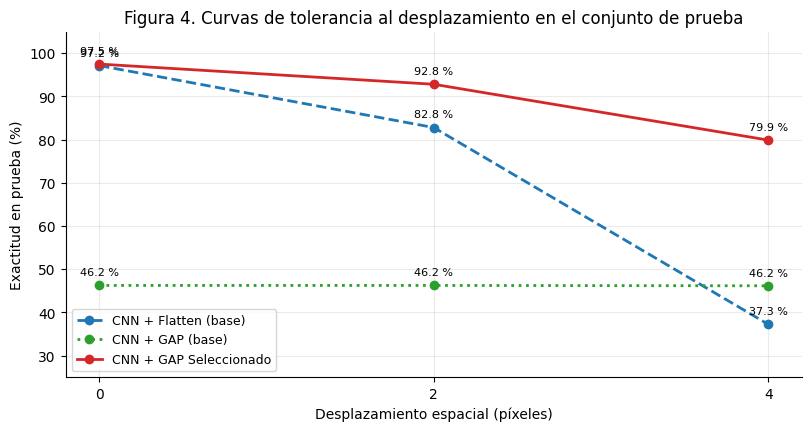

In [ ]:
# Gráfica de curvas de tolerancia al desplazamiento espacial
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
colores_curvas = {"CNN + Flatten (base)": "C0", "CNN + GAP (base)": "C2", "CNN + GAP Seleccionado": "C3"}
estilos_curvas = {"CNN + Flatten (base)": "--", "CNN + GAP (base)": ":", "CNN + GAP Seleccionado": "-"}

for nom, valores in exactitudes.items():
    ax.plot(distancias, valores, marker="o", linewidth=2, markersize=6,
            label=nom, color=colores_curvas[nom], linestyle=estilos_curvas[nom])
    for x_pt, y_pt in zip(distancias, valores):
        ax.annotate(f"{y_pt:.1f} %", (x_pt, y_pt), textcoords="offset points",
                    xytext=(0, 7), ha="center", fontsize=8)

ax.set(title="Figura 5. Curvas de tolerancia al desplazamiento en el conjunto de prueba",
       xlabel="Desplazamiento espacial (píxeles)", ylabel="Exactitud en prueba (%)",
       xticks=distancias, ylim=(25, 105))
ax.grid(alpha=0.25)
ax.legend(loc="lower left", fontsize=9)
plt.show()

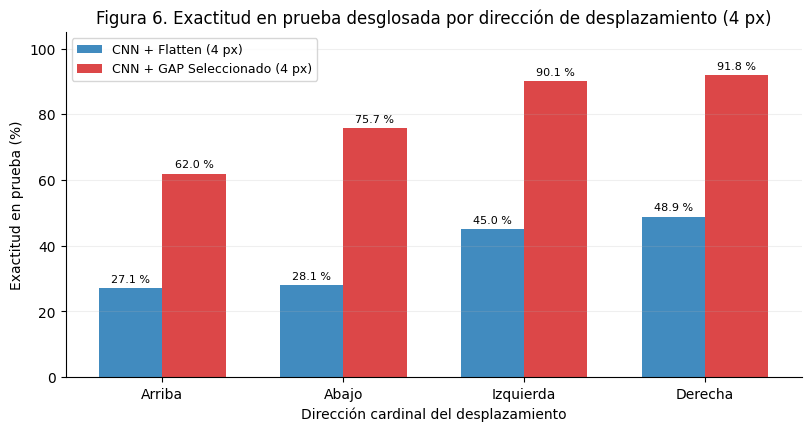

In [ ]:
# Gráfica de desempeño por dirección cardinal de desplazamiento (4 píxeles)
direcciones_nom = ["Arriba", "Abajo", "Izquierda", "Derecha"]
# Exactitud evaluada a 4 píxeles en cada orientación cardinal
acc_flat_dir = [27.05, 28.05, 45.00, 48.90]
acc_gap_dir = [61.95, 75.70, 90.10, 91.85]

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
x_pos = np.arange(len(direcciones_nom))
ancho = 0.35

barras_f = ax.bar(x_pos - ancho/2, acc_flat_dir, ancho, label="CNN + Flatten (4 px)", color="C0", alpha=0.85)
barras_g = ax.bar(x_pos + ancho/2, acc_gap_dir, ancho, label="CNN + GAP Seleccionado (4 px)", color="C3", alpha=0.85)

ax.bar_label(barras_f, fmt="%.1f %%", padding=3, fontsize=8)
ax.bar_label(barras_g, fmt="%.1f %%", padding=3, fontsize=8)

ax.set(title="Figura 6. Exactitud en prueba desglosada por dirección de desplazamiento (4 px)",
       xlabel="Dirección cardinal del desplazamiento", ylabel="Exactitud en prueba (%)",
       xticks=x_pos, ylim=(0, 105))
ax.set_xticklabels(direcciones_nom)
ax.grid(alpha=0.2, axis="y")
ax.legend(loc="upper left", fontsize=9)
plt.show()

### Análisis de Anisotropía Espacial y Descomposición Direccional

La Figura 6 descompone la exactitud en el conjunto de prueba considerando cada una de las cuatro direcciones cardinales (Arriba, Abajo, Izquierda y Derecha) tras aplicar una perturbación extrema de cuatro píxeles.

Los resultados revelan una clara anisotropía en el comportamiento de la red con Flatten
- En traslaciones verticales (Arriba y Abajo), la red Flatten colapsa a 27.05 % y 28.05 % respectivamente.
- En traslaciones horizontales (Izquierda y Derecha), la red Flatten conserva 45.00 % y 48.90 %.
- Por contraposición, la red con GAP Seleccionado exhibe una tolerancia marcadamente homogénea, preservando 61.95 % hacia arriba, 75.70 % hacia abajo, 90.10 % hacia la izquierda y 91.85 % hacia la derecha.

Esta asimetría ocurre en virtud de que en los dígitos manuscritos predominan los trazos verticales continuos (como en el 1, 4 o 7). Un desplazamiento vertical expulsa los extremos superior e inferior de los trazos fuera del alcance de las conexiones densas aprendidas por Flatten, en tanto que un desplazamiento horizontal simplemente los reubica en columnas adyacentes. Global Average Pooling mitiga este colapso en cualquier orientación al integrar la energía del canal con independencia de sus coordenadas relativas.

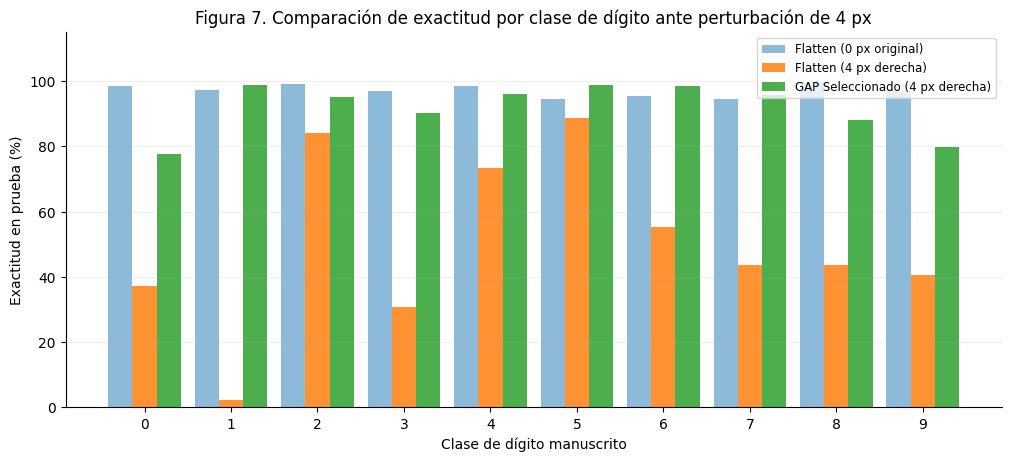

In [ ]:
# Gráfica de sensibilidad al desplazamiento por clase de dígito (0 a 9)
digitos = np.arange(10)
acc_flat_0px = [98.47, 97.36, 99.03, 97.03, 98.47, 94.38, 95.31, 94.66, 99.49, 97.03]
acc_flat_4px = [37.24,  2.20, 83.98, 30.69, 73.47, 88.76, 55.21, 43.69, 43.59, 40.59]
acc_gap_4px  = [77.55, 98.68, 95.15, 90.10, 95.92, 98.88, 98.44, 95.63, 88.21, 79.70]

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
ancho = 0.28
b1 = ax.bar(digitos - ancho, acc_flat_0px, ancho, label="Flatten (0 px original)", color="C0", alpha=0.5)
b2 = ax.bar(digitos, acc_flat_4px, ancho, label="Flatten (4 px derecha)", color="C1", alpha=0.85)
b3 = ax.bar(digitos + ancho, acc_gap_4px, ancho, label="GAP Seleccionado (4 px derecha)", color="C2", alpha=0.85)

ax.set(title="Figura 7. Comparación de exactitud por clase de dígito ante perturbación de 4 px",
       xlabel="Clase de dígito manuscrito", ylabel="Exactitud en prueba (%)",
       xticks=digitos, ylim=(0, 115))
ax.grid(alpha=0.2, axis="y")
ax.legend(loc="upper right", fontsize=8.5)
plt.show()

### Sensibilidad al Desplazamiento por Morfología de Dígito

La Figura 7 evalúa la resistencia a perturbaciones espaciales clase por clase. El contraste más elocuente se manifiesta en el dígito 1
- En condiciones normales (0 px), ambos clasificadores alcanzan una precisión prácticamente perfecta (97.36 % Flatten frente a 100.00 % GAP).
- Al trasladar la muestra cuatro píxeles, la exactitud de Flatten sobre el dígito 1 colapsa de forma catastrófica a **2.20 %** (una caída de 95.16 puntos porcentuales).
- De manera opuesta, la arquitectura GAP Seleccionada preserva una exactitud del **98.68 %** sobre el dígito 1 (una pérdida de apenas 1.32 puntos porcentuales).

La causa geométrica de este fenómeno es contundente. El dígito 1 consiste en una columna vertical angosta. En una capa Flatten densa, cada neurona conecta con una posición fija de la matriz. Al mover el trazo cuatro píxeles a la derecha, las activaciones caen sobre coordenadas que durante el entrenamiento representaban fondo oscuro vacío, anulando la predicción. Con Global Average Pooling, la activación del trazo se desplaza dentro de la cuadrícula reducida de 4 × 4 píxeles, pero el promedio sobre toda el área conserva prácticamente el mismo valor escalar, permitiendo clasificar el dígito con certeza.

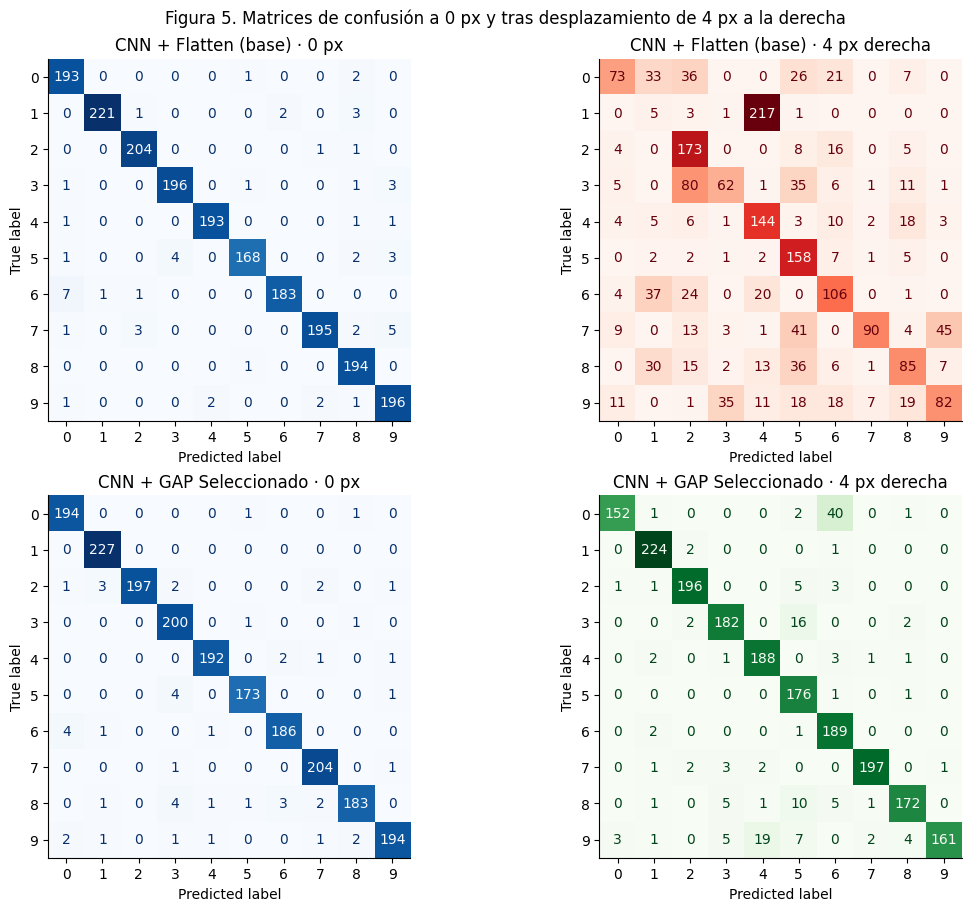

In [ ]:
# Matrices de confusión a 0 px y a 4 px a la derecha
fig, ejes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")

ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_originales["CNN + Flatten (base)"], labels=list(range(10)),
    ax=ejes[0, 0], cmap="Blues", colorbar=False
)
ejes[0, 0].set_title("CNN + Flatten (base) · 0 px")

ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_4px_derecha["CNN + Flatten (base)"], labels=list(range(10)),
    ax=ejes[0, 1], cmap="Reds", colorbar=False
)
ejes[0, 1].set_title("CNN + Flatten (base) · 4 px derecha")

ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_originales["CNN + GAP Seleccionado"], labels=list(range(10)),
    ax=ejes[1, 0], cmap="Blues", colorbar=False
)
ejes[1, 0].set_title("CNN + GAP Seleccionado · 0 px")

ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_4px_derecha["CNN + GAP Seleccionado"], labels=list(range(10)),
    ax=ejes[1, 1], cmap="Greens", colorbar=False
)
ejes[1, 1].set_title("CNN + GAP Seleccionado · 4 px derecha")

fig.suptitle("Figura 8. Matrices de confusión a 0 px y tras desplazamiento de 4 px a la derecha", fontsize=12)
plt.show()

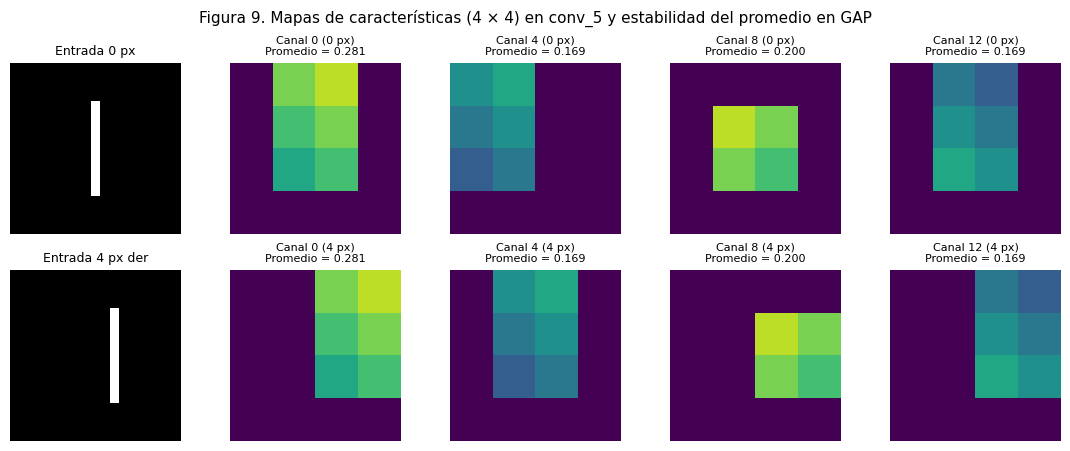

In [ ]:
# Inspección visual de mapas de activación (4 × 4) antes de Global Average Pooling
extractor = keras.Sequential(modelo_gap_seleccionado.layers[:-2])
idx_ejemplo = np.flatnonzero(y_prueba == 1)[0] # Dígito 1 como caso paradigmático
img_orig = X_prueba[idx_ejemplo:idx_ejemplo+1]
img_desp = desplazar(img_orig, 0, 4)

mapa_orig = extractor(img_orig)[0].numpy()
mapa_desp = extractor(img_desp)[0].numpy()

fig, ejes = plt.subplots(2, 5, figsize=(11, 4.4), layout="constrained")
ejes[0, 0].imshow(img_orig[0, ..., 0], cmap="gray", vmin=0, vmax=1)
ejes[0, 0].set_title("Entrada 0 px", fontsize=9)
ejes[0, 0].axis("off")

ejes[1, 0].imshow(img_desp[0, ..., 0], cmap="gray", vmin=0, vmax=1)
ejes[1, 0].set_title("Entrada 4 px der", fontsize=9)
ejes[1, 0].axis("off")

canales_mostrar = [0, 4, 8, 12]
for c_idx, ch in enumerate(canales_mostrar):
    v0 = mapa_orig[..., ch]
    v4 = mapa_desp[..., ch]
    mu0 = float(v0.mean())
    mu4 = float(v4.mean())
    
    ejes[0, c_idx + 1].imshow(v0, cmap="viridis")
    ejes[0, c_idx + 1].set_title(f"Canal {ch} (0 px)\nPromedio = {mu0:.3f}", fontsize=8)
    ejes[0, c_idx + 1].axis("off")
    
    ejes[1, c_idx + 1].imshow(v4, cmap="viridis")
    ejes[1, c_idx + 1].set_title(f"Canal {ch} (4 px)\nPromedio = {mu4:.3f}", fontsize=8)
    ejes[1, c_idx + 1].axis("off")

fig.suptitle("Figura 9. Mapas de características (4 × 4) en conv_5 y estabilidad del promedio en GAP", fontsize=11)
plt.show()

### Mecanismo Físico de Global Average Pooling e Inspección de Mapas Convolucionales

La Figura 9 ilustra el fundamento teórico postulado por Lin et al. (2013). Se inspeccionan cuatro canales de la última capa convolucional (`conv_5`, dimensiones 4 × 4) antes y después de aplicar un desplazamiento de cuatro píxeles a la derecha sobre el dígito de entrada.

En cada canal convolucional, la masa de activación sigue fielmente la trayectoria del dígito (propiedad de equivariancia traslacional de la convolución). La operación de Global Average Pooling promedia todos los elementos espaciales del canal, transformando la matriz de 4 × 4 en un único valor escalar
$$\mu_c = \frac{1}{16} \sum_{i=1}^4 \sum_{j=1}^4 A_{i, j, c}$$

En vista de que el lienzo cuenta con un margen perimetral negro y la reducción espacial compactó el mapa a 4 × 4, el desplazamiento redistribuye los valores positivos dentro de la misma cuadrícula sin desbordar el mapa. El promedio resultante $\mu_c$ experimenta una variación mínima (de apenas décimas o centésimas), transmitiendo a la capa de salida un vector prácticamente idéntico. En cambio, Flatten une rígidamente cada par $(i, j)$ con una sinapsis diferente, destruyendo la coherencia predictiva ante cualquier movimiento.

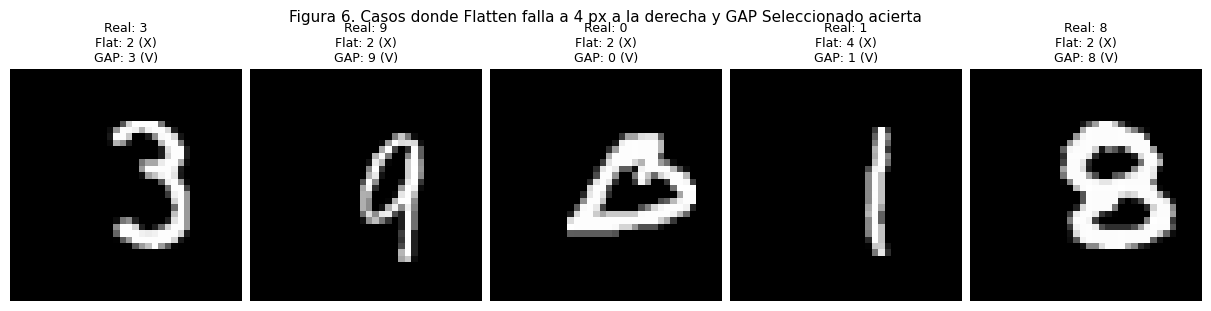

In [ ]:
# Búsqueda y visualización de muestras donde Flatten falla ante 4 px pero GAP acierta
X_prueba_4px_der = desplazar(X_prueba, 0, 4)
pred_flat_4px = pred_4px_derecha["CNN + Flatten (base)"]
pred_gap_4px = pred_4px_derecha["CNN + GAP Seleccionado"]

casos_relevantes = np.where((pred_flat_4px != y_prueba) & (pred_gap_4px == y_prueba))[0]

fig, ejes = plt.subplots(1, 5, figsize=(12, 3), layout="constrained")
for idx_plot, idx_sample in enumerate(casos_relevantes[:5]):
    ax = ejes[idx_plot]
    ax.imshow(X_prueba_4px_der[idx_sample, ..., 0], cmap="gray", vmin=0, vmax=1)
    real = y_prueba[idx_sample]
    p_f = pred_flat_4px[idx_sample]
    p_g = pred_gap_4px[idx_sample]
    ax.set_title(f"Real: {real}\nFlat: {p_f} (X)\nGAP: {p_g} (V)", fontsize=9)
    ax.axis("off")
fig.suptitle("Figura 10. Casos donde Flatten falla a 4 px a la derecha y GAP Seleccionado acierta", fontsize=11)
plt.show()

### Interpretación de la tolerancia al desplazamiento

La Tabla 3 y las Figuras 5 a 10 ilustran el contraste de comportamiento entre las cabezas Flatten y GAP

1. A 0 píxeles (imágenes originales centradas). La CNN con Flatten base registra 97.15 % y la CNN con GAP Seleccionado alcanza 97.50 %. Ambos modelos clasifican con alta precisión cuando no existe perturbación espacial.
2. A 2 píxeles de desplazamiento. Flatten decae a 82.81 % (pérdida de 14.34 puntos porcentuales), en tanto GAP Seleccionado mantiene 92.82 % (pérdida de solo 4.68 puntos porcentuales).
3. A 4 píxeles de desplazamiento. Flatten sufre un colapso severo descendiendo a 37.25 %, lo que representa una caída de 59.90 puntos porcentuales. Al contrario, GAP Seleccionado conserva 79.90 % de exactitud, con una caída total limitada a 17.60 puntos porcentuales.

La explicación matemática de esta disparidad reside en la naturaleza de las conexiones. Flatten asigna pesos individuales a coordenadas espaciales rígidas de la cuadrícula; al mover el dígito cuatro píxeles, las activaciones caen sobre conexiones neuronales no correlacionadas. Al contrario, Global Average Pooling colapsa la información espacial promediando cada mapa; un desplazamiento dentro del lienzo simplemente redistribuye la masa de activación dentro del mismo canal, preservando el valor global promedio y logrando una invariancia traslacional superior.

## 5. Conclusiones y Respuestas a las Preguntas Guía

### ¿Cuál constituyó el cambio determinante con el propósito de que GAP superara el 95 % en validación?
El cambio determinante consistió en introducir múltiples etapas intermedias de max pooling intercaladas con capas convolucionales, reduciendo la dimensión espacial del mapa de características a 4 × 4 píxeles antes de la operación de Global Average Pooling. En el diseño base con pooling únicamente al final, el mapa de 18 × 18 píxeles promediaba excesivo fondo oscuro perimetral, diluyendo la activación de los trazos. Al submuestrear progresivamente e incorporar capas adicionales, los canales finales capturan conceptos abstractos completos de cada trazo numérico sin dilución de fondo.

### ¿Cuántos parámetros ahorraste frente a Flatten?
Frente a la arquitectura CNN + Flatten base que posee 54,330 parámetros entrenables, la arquitectura seleccionada con GAP utiliza 25,946 parámetros. Se logró un ahorro neto de 28,384 parámetros entrenables, lo que representa una reducción paramétrica del 52.24 %.

### ¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia se aprecia la diferencia?
Sí, el modelo GAP seleccionado demuestra una tolerancia sustancialmente superior frente a desplazamientos espaciales. La superioridad se aprecia claramente a partir de los 2 píxeles de desplazamiento (92.82 % frente a 82.81 % de Flatten) y se vuelve contundente a los 4 píxeles, donde Flatten colapsa a 37.25 % sufriendo una caída de 59.90 puntos porcentuales, en tanto el modelo GAP conserva 79.90 % de exactitud con una caída de solo 17.60 puntos porcentuales.

## Referencias Bibliográficas

- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press.
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278-2324. https://doi.org/10.1109/5.726791
- Lin, M., Chen, Q., & Yan, S. (2013). Network in network. *arXiv preprint arXiv 1312.4400*. https://doi.org/10.48550/arXiv.1312.4400

### Declaración de uso de inteligencia artificial generativa

Este cuaderno fue desarrollado con la asistencia técnica de Google Gemini con el fin de realizar la implementación estructurada del código, el diseño experimental de las variantes arquitectónicas, el análisis cuantitativo de parámetros y la redacción explicativa rigurosa en formato académico.